## Лабораторная работа № 1
### Часть 2. Разведочный анализ Cooking Time

Объект наблюдения — заказ в ресторане. Целевая переменная `cooking_time_minutes` — фактическая длительность приготовления в минутах.

Выполним пункты задания: определим типы признаков, исследуем и устраним пропуски и выбросы, рассчитаем статистики, построим распределения важных признаков и корреляции.

Данные читаются из таблицы Iceberg, созданной первой частью. Исходный файл загружается в HDFS **отдельно в терминале сервера** командой `hdfs dfs -copyFromLocal`, описанной в первой части. Этот ноутбук ничего не копирует.

Ячейки выполняются сверху вниз на сервере с Spark 3.5 / Scala 2.12 и YARN. Расчёты выполняются на всей таблице; для графиков на драйвер передаются только ограниченные сводки. Код намеренно использует отдельные фильтры и подсчёты, поэтому на большом датасете потребуется время.

### 1. Подключение библиотек и Spark
Используем функции PySpark для расчётов и Matplotlib для графиков. Обучение моделей в эту часть работы не входит.

In [1]:
import os  # Имя пользователя сервера.
import math  # Проверка, что результат корреляции — конечное число.
from pyspark import SparkConf  # Настройки Spark.
from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as F  # Функции для столбцов.
import matplotlib.pyplot as plt  # Построение графиков.

### Выбор параметров анализа

В Cooking Time 186 числовых признаков и 6 категориальных признаков. Вывести подробные графики для всех числовых столбцов и всех категорий на одном этапе неудобно. Поэтому зададим отдельно правило обработки пропусков и ограничения объёма визуализации.

**`missing_threshold = 0.50` — правило исключения числового признака.**

Для каждого `num_*` рассчитываем долю пропусков: число NULL, делённое на число строк после очистки целевой переменной. Если доля **больше 50%**, удаляем столбец. При доле ровно 50% столбец сохраняется.

Порог выбран так, чтобы в сохранённом столбце число наблюдаемых значений было не меньше числа восстанавливаемых. Иначе большая часть столбца после заполнения могла бы состоять из одной искусственно подставленной медианы. Для обезличенных признаков у нас нет предметного основания восстанавливать столь значительную часть данных.

Это объясняет принятое правило, но **не доказывает оптимальность порога 50%**. Даже сильно разреженный признак может содержать полезную информацию. Поэтому перед удалением показываем фактическую долю пропусков каждого столбца, а в итогах указываем потери признаков. Для этой работы порог служит явным упрощением очистки.

**`top_features_count = 5` — число числовых признаков для подробных рисунков.**

Выбираем 5 числовых признаков, наиболее сильно коррелирующих со временем приготовления. Учитываем как положительную, так и отрицательную корреляцию.

**`top_categories_count = 15` — число категорий на одном рисунке.**

У части `cat_*` много различных кодов. Выбираем до 15 самых частых категорий, чтобы подписи оставались читаемыми, а частоты и среднее время можно было сравнить на паре графиков. Если категорий меньше 15, показываем все.


In [2]:
# База и входная таблица должны совпадать с первой частью.
user_name = os.getenv("USER")
database_name = "cooking_time_database"
source_table = f"spark_catalog.{database_name}.sobd_lab1_cooking_time"
processed_table = f"spark_catalog.{database_name}.sobd_lab1_cooking_time_processed"
target_col = "cooking_time_minutes"
timestamp_col = "timestamp"

# Это выбранные правила анализа, а не свойства предметной области.
missing_threshold = 0.50  # Удаляем числовые признаки, где пропущено больше половины значений.
top_features_count = 5  # Для подробных графиков выбираем до пяти числовых признаков.
top_categories_count = 15  # Показываем до 15 наиболее частых категорий.

In [3]:
# Объявляем функцию без аргументов. -> SparkConf — подсказка о типе возвращаемого результата.
def create_spark_configuration() -> SparkConf:
    """Настройки Spark 3.5 и Iceberg для учебного кластера."""
    # Создаём пустой набор настроек и ниже заполняем его.
    conf = SparkConf()
    # Имя приложения, по которому его можно найти в Spark UI и YARN.
    conf.setAppName("lab 1 Cooking Time - exploratory analysis")
    # YARN распределяет ресурсы Hadoop-кластера; вычисления будут выполняться на кластере.
    conf.setMaster("yarn")
    # Режим client: драйвер управляет работой из процесса ноутбука, исполнители выполняют задачи на кластере.
    conf.set("spark.submit.deployMode", "client")
    # Каждому исполнителю запрашиваем 12 ГБ оперативной памяти.
    conf.set("spark.executor.memory", "12g")
    # Каждому исполнителю выделяем 8 процессорных ядер.
    conf.set("spark.executor.cores", "8")
    # Запрашиваем 2 исполнителя: вместе это 16 ядер; фактическое выделение зависит от кластера.
    conf.set("spark.executor.instances", "2")
    # Запрашиваем 4 ГБ для драйвера. В client-режиме лимит памяти JVM задают до её запуска.
    conf.set("spark.driver.memory", "4g") # память драйвера: 4 ГБ; он принимает результаты collect() и toPandas(), поэтому не стоит просить у него слишком много данных
    conf.set("spark.driver.cores", "2")
    # Подключаем Iceberg 1.6.0 для Spark 3.5 и Scala 2.12: библиотека нужна для чтения и записи таблиц.
    conf.set("spark.jars.packages",
             "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
    # Включаем расширения Spark SQL для работы с Iceberg.
    conf.set("spark.sql.extensions",
             "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    # Назначаем каталогу spark_catalog реализацию Iceberg, которая знает формат этих таблиц.
    conf.set("spark.sql.catalog.spark_catalog",
             "org.apache.iceberg.spark.SparkCatalog")
    # Метаданные таблиц будут храниться в файловой системе, без отдельного сервера каталога.
    conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
    # Папка в HDFS для файлов и метаданных наших таблиц; имя пользователя подставится автоматически.
    conf.set("spark.sql.catalog.spark_catalog.warehouse",
             f"hdfs:///user/{user_name}/warehouse")
    # Указываем класс, через который Iceberg будет читать и записывать файлы Hadoop/HDFS.
    conf.set("spark.sql.catalog.spark_catalog.io-impl",
             "org.apache.iceberg.hadoop.HadoopFileIO")
    # Возвращаем готовые настройки туда, откуда была вызвана функция.
    return conf

# Вызываем функцию: теперь переменная conf хранит все перечисленные настройки.
conf = create_spark_configuration()

# Создаём сессию с теми же настройками каталога Iceberg, что в первой части.
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

:: loading settings :: url = jar:file:/opt/spark-3.5.2-bin-hadoop3/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /home/user0/.ivy2/cache
The jars for the packages stored in: /home/user0/.ivy2/jars
org.apache.iceberg#iceberg-spark-runtime-3.5_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-81194c15-d8c8-4edf-b308-b30c111c4343;1.0
	confs: [default]
	found org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 in central
:: resolution report :: resolve 567ms :: artifacts dl 21ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-3.5_2.12;1.6.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   1   |   0   |   0   |   0   ||   1   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spa

### 2. Типы признаков и исходные данные
Числовые `num_*` — количественные признаки. `bin_*` принимают два состояния. `cat_*` — коды категорий, для которых среднее арифметическое не имеет предметного смысла. Временную метку используем для анализа периода наблюдений.

In [4]:
# Читаем результат первой части.
df = spark.table(source_table)
num_cols = []
bin_cols = []
cat_cols = []
for column in df.columns:
    if column.startswith("num_"):
        num_cols.append(column)
    elif column.startswith("bin_"):
        bin_cols.append(column)
    elif column.startswith("cat_"):
        cat_cols.append(column)

df.printSchema()
preview_cols = num_cols[:5] + bin_cols + cat_cols + [timestamp_col, target_col]
df.select(preview_cols).show(5, truncate=30)
initial_rows = df.count()
print(f"Исходных строк: {initial_rows}")
print(f"Числовых признаков: {len(num_cols)}")
print(f"Бинарных признаков: {len(bin_cols)}")
print(f"Категориальных признаков: {len(cat_cols)}")

root
 |-- num_0: float (nullable = true)
 |-- num_1: float (nullable = true)
 |-- num_2: float (nullable = true)
 |-- num_3: float (nullable = true)
 |-- num_4: float (nullable = true)
 |-- num_5: float (nullable = true)
 |-- num_6: float (nullable = true)
 |-- num_7: float (nullable = true)
 |-- num_8: float (nullable = true)
 |-- num_9: float (nullable = true)
 |-- num_10: float (nullable = true)
 |-- num_11: float (nullable = true)
 |-- num_12: float (nullable = true)
 |-- num_13: float (nullable = true)
 |-- num_14: float (nullable = true)
 |-- num_15: float (nullable = true)
 |-- num_16: float (nullable = true)
 |-- num_17: float (nullable = true)
 |-- num_18: float (nullable = true)
 |-- num_19: float (nullable = true)
 |-- num_20: float (nullable = true)
 |-- num_21: float (nullable = true)
 |-- num_22: float (nullable = true)
 |-- num_23: float (nullable = true)
 |-- num_24: float (nullable = true)
 |-- num_25: float (nullable = true)
 |-- num_26: float (nullable = true)
 |-- n

+----------+-----------+-----------+----------+----------+-----+-----+-----+-----+-----+-----+-----+-----+-----+-------------------+--------------------+
|     num_0|      num_1|      num_2|     num_3|     num_4|bin_0|bin_1|bin_2|cat_0|cat_1|cat_2|cat_3|cat_4|cat_5|          timestamp|cooking_time_minutes|
+----------+-----------+-----------+----------+----------+-----+-----+-----+-----+-----+-----+-----+-----+-----+-------------------+--------------------+
|0.57311535|0.031369343|  0.5770625|0.10388375| 1.9302471|  0.0|  1.0|  1.0| 5813| 2247| 3155|  136|    1|    2|2023-11-23 13:14:01|           36.533333|
|0.57311535|0.031369343| 0.35348615| 1.5002738|-1.4034932|  0.0|  1.0|  1.0| 1492|  655| 1190|  840|    1|    2|2023-11-23 13:15:59|           7.9166665|
|0.57311535|0.031369343|-0.15238884|0.18254659| 1.0364627|  0.0|  1.0|  0.0|14024| 2862| 1124| 4384|    1|    2|2023-11-23 13:19:42|           11.966666|
|-0.6815943|0.031369343|-0.51449364|  1.679574| 1.7880672|  1.0|  1.0|  1.0|

Исходных строк: 12799642
Числовых признаков: 186
Бинарных признаков: 3
Категориальных признаков: 6


### 3. Исходные пропуски
Первая часть уже заменила обнаруженные NaN на NULL. Теперь подсчитаем пропуски до очистки. Функция использует одну простую последовательность: отобрать пустые значения → посчитать строки → вычислить долю.

In [5]:
def missing_summary(data, row_count):
    counts = {}
    for column in data.columns:
        missing_rows = data.filter(F.col(column).isNull())
        missing_count = missing_rows.count()
        counts[column] = missing_count
        if missing_count > 0:
            share = 0.0
            if row_count > 0:
                share = missing_count / row_count
            print(f"{column}: {missing_count} пропусков ({share:.2%})")
    return counts

missing_before = missing_summary(df, initial_rows)

num_33: 39 пропусков (0.00%)


num_40: 193 пропусков (0.00%)


num_47: 37 пропусков (0.00%)


num_54: 76 пропусков (0.00%)
num_61: 120 пропусков (0.00%)
num_68: 26 пропусков (0.00%)


num_75: 311 пропусков (0.00%)
num_131: 1103 пропусков (0.01%)
num_132: 1103 пропусков (0.01%)
num_133: 1103 пропусков (0.01%)
num_134: 1103 пропусков (0.01%)
num_135: 1103 пропусков (0.01%)
num_136: 1103 пропусков (0.01%)
num_137: 1103 пропусков (0.01%)
num_138: 1103 пропусков (0.01%)
num_139: 3476214 пропусков (27.16%)
num_140: 3476214 пропусков (27.16%)
num_141: 3476214 пропусков (27.16%)
num_142: 3476214 пропусков (27.16%)
num_143: 1103 пропусков (0.01%)
num_144: 1103 пропусков (0.01%)
num_145: 3554539 пропусков (27.77%)
num_146: 3554539 пропусков (27.77%)
num_147: 3554539 пропусков (27.77%)
num_148: 3554539 пропусков (27.77%)
num_149: 1103 пропусков (0.01%)
num_150: 3318267 пропусков (25.92%)


num_151: 3318267 пропусков (25.92%)
num_152: 3318267 пропусков (25.92%)
num_153: 3318267 пропусков (25.92%)
num_154: 3318267 пропусков (25.92%)
num_155: 6036378 пропусков (47.16%)
num_156: 6036378 пропусков (47.16%)
num_157: 6036378 пропусков (47.16%)
num_158: 6036378 пропусков (47.16%)
num_159: 6036378 пропусков (47.16%)
num_160: 3360353 пропусков (26.25%)
num_161: 3360353 пропусков (26.25%)
num_162: 3360353 пропусков (26.25%)
num_163: 3360353 пропусков (26.25%)
num_164: 3360353 пропусков (26.25%)
num_165: 12672509 пропусков (99.01%)
num_166: 12672509 пропусков (99.01%)
num_167: 12672509 пропусков (99.01%)
num_168: 12672509 пропусков (99.01%)
num_169: 12672509 пропусков (99.01%)
num_170: 3318267 пропусков (25.92%)
num_171: 3318267 пропусков (25.92%)
num_172: 3318267 пропусков (25.92%)
num_173: 3318267 пропусков (25.92%)
num_174: 3318267 пропусков (25.92%)
num_175: 3318267 пропусков (25.92%)
num_176: 3318267 пропусков (25.92%)
num_177: 3318267 пропусков (25.92%)
num_178: 3318267 пропус

### 4. Проверка целевой переменной и времени

Отрицательная длительность приготовления не имеет физического смысла, поэтому удалим их. Также удалим строки с отсутствующей целью: заполнять фактическое время приготовления средним или медианой означало бы придумывать ответ.

Для временного анализа нужны наблюдения с известным `timestamp`, поэтому строки без него исключаем с отдельным подсчётом. Нулевое время пока сохраняем: из доступного описания нельзя установить, обязательно ли это ошибка.

In [6]:
# Сначала показываем обнаруженную проблему.
negative_rows = df.filter(F.col(target_col) < 0)
negative_rows.select(timestamp_col, target_col).show(10, truncate=False)
negative_count = negative_rows.count()
print(f"Отрицательных длительностей: {negative_count}")

# Каждое правило выполняем отдельно, чтобы видеть причины удаления строк.
missing_target_count = df.filter(F.col(target_col).isNull()).count()
df = df.filter(F.col(target_col).isNotNull())
df = df.filter(F.col(target_col) >= 0)

missing_time_count = df.filter(F.col(timestamp_col).isNull()).count()
df = df.filter(F.col(timestamp_col).isNotNull())

valid_rows = df.count()
print(f"Удалено строк без цели: {missing_target_count}")
print(f"Удалено строк без временной метки после проверки цели: {missing_time_count}")
print(f"Осталось строк: {valid_rows}")

+-------------------+--------------------+
|timestamp          |cooking_time_minutes|
+-------------------+--------------------+
|2023-12-26 13:26:47|-0.6666667          |
|2023-12-24 17:58:19|-0.05               |
|2023-12-21 20:31:30|-0.033333335        |
|2023-12-26 14:29:16|-2.1166666          |
|2023-12-24 16:54:42|-0.033333335        |
|2023-12-21 11:49:57|-0.78333336         |
|2023-12-21 12:45:02|-0.016666668        |
|2023-12-21 13:11:33|-0.8                |
|2023-12-21 13:16:49|-0.13333334         |
|2024-01-03 10:55:08|-0.033333335        |
+-------------------+--------------------+
only showing top 10 rows

Отрицательных длительностей: 25


Удалено строк без цели: 0
Удалено строк без временной метки после проверки цели: 0
Осталось строк: 12799617


### 5. Статистика и графики времени приготовления до удаления выбросов

Рассчитаем минимум, максимум, среднее, стандартное отклонение, квартили и 95-й процентиль.

**Квантиль** задаётся долей от 0 до 1, **процентиль** — процентом от 0 до 100.

| Обозначение | Название | Доля данных |
|---|---|---|
| Q1 | Первый квартиль | 25% |
| Q2 | Второй квартиль, медиана | 50% |
| Q3 | Третий квартиль | 75% |
| P95 | 95-й процентиль | 95% |

**Ранг — позиция значения в упорядоченном ряду.**

В `approxQuantile(..., 0.001)` допускается отклонение ранга примерно на 0,1% от числа непустых значений. Приближённый расчёт выбран для снижения вычислительных затрат. NULL не участвуют в расчёте.

In [7]:
def column_statistics(data, column):
    # describe() выводит количество непустых значений, среднее, отклонение, минимум и максимум.
    data.select(column).describe().show()

    non_empty = data.filter(F.col(column).isNotNull())
    quantiles = non_empty.approxQuantile(column, [0.25, 0.50, 0.75, 0.95], 0.001)
    statistics = {}
    if len(quantiles) == 4:
        statistics["q1"] = quantiles[0]
        statistics["median"] = quantiles[1]
        statistics["q3"] = quantiles[2]
        statistics["p95"] = quantiles[3]
        print(f"{column}: Q1={quantiles[0]:.3f}, медиана={quantiles[1]:.3f}")
        print(f"{column}: Q3={quantiles[2]:.3f}, P95={quantiles[3]:.3f}")
    return statistics

target_statistics = column_statistics(df, target_col)

+-------+--------------------+
|summary|cooking_time_minutes|
+-------+--------------------+
|  count|            12799617|
|   mean|  15.775077556588073|
| stddev|   10.67205708284833|
|    min|                 0.0|
|    max|               120.0|
+-------+--------------------+



cooking_time_minutes: Q1=8.033, медиана=13.133
cooking_time_minutes: Q3=20.717, P95=36.183


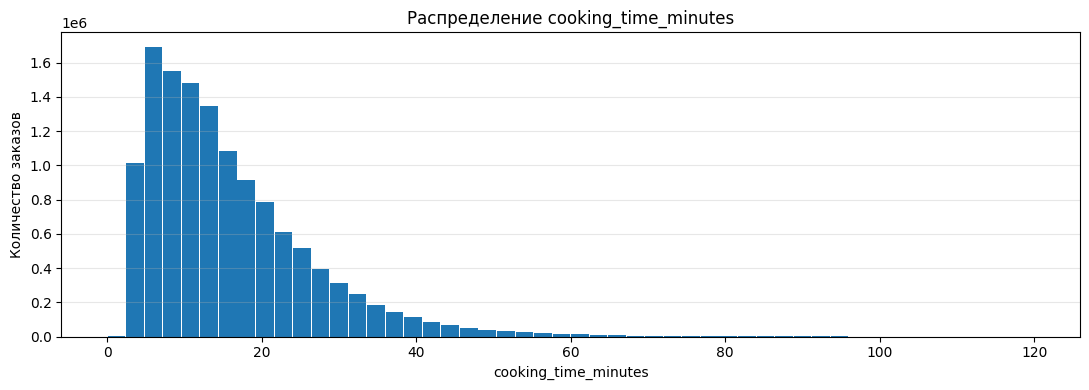

In [8]:
def plot_histogram(data, column, bins=50):
    # Выбираем непустые значения одного столбца.
    values = data.filter(F.col(column).isNotNull())
    minimum = values.select(F.min(column)).first()[0]
    maximum = values.select(F.max(column)).first()[0]
    if minimum is None:
        return

    fig, ax = plt.subplots(figsize=(11, 4))
    if minimum == maximum:
        # Для постоянного признака нет диапазона: показываем один столбик.
        ax.bar([minimum], [values.count()])
    else:
        width = (maximum - minimum) / bins
        # Каждой строке назначаем номер интервала.
        values = values.withColumn("histogram_bucket",
                                   F.floor((F.col(column) - minimum) / width))
        # Максимальное значение помещаем в последний интервал.
        values = values.withColumn(
            "histogram_bucket",
            F.when(F.col("histogram_bucket") >= bins, bins - 1)
             .otherwise(F.col("histogram_bucket"))
        )
        frequencies = values.groupBy("histogram_bucket").count()
        frequencies = frequencies.orderBy("histogram_bucket")
        # Передаём на драйвер максимум bins строк, а не весь датасет.
        rows = frequencies.collect()
        centers = []
        counts = []
        for row in rows:
            center = minimum + (row["histogram_bucket"] + 0.5) * width
            centers.append(center)
            counts.append(row["count"])
        ax.bar(centers, counts, width=width * 0.95)

    ax.set_xlabel(column)
    ax.set_ylabel("Количество заказов")
    ax.set_title(f"Распределение {column}")
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_histogram(df, target_col)

`IQR = Q3 − Q1` — межквартильный размах

**Правило Тьюки** отмечает потенциальные выбросы за границами `Q1 − 1,5 × IQR` и `Q3 + 1,5 × IQR`, где `IQR = Q3 − Q1` — ширина центральных 50% данных. Коэффициент **1,5** — принятое практическое правило, а не величина, рассчитанная по нашему датасету. Выход за границы означает статистически необычное значение, но не доказывает ошибку; удаление таких строк — выбранное правило очистки

Ящик с усами строим по статистикам всей таблицы. Усы заканчиваются на крайних фактических значениях внутри указанных границ. Для отображения точек за границами берём не более 100 наблюдений.

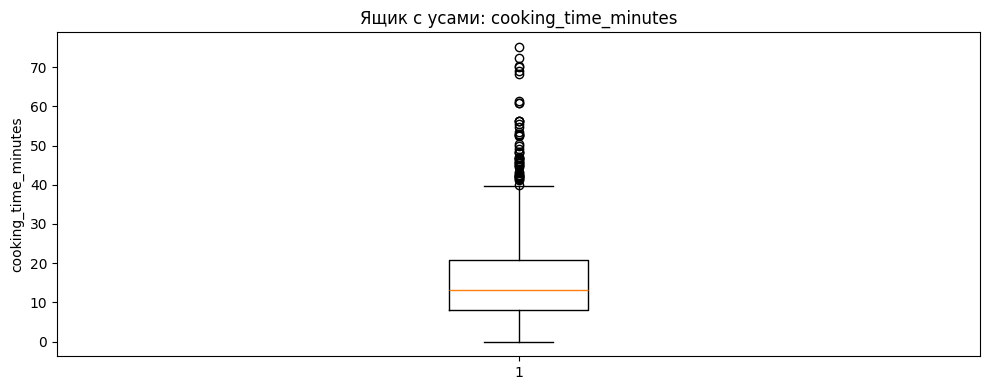

In [9]:
def plot_boxplot(data, column, statistics):
    if len(statistics) == 0:
        return
    q1 = statistics["q1"]
    q3 = statistics["q3"]
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    inside = data.filter(F.col(column) >= lower)
    inside = inside.filter(F.col(column) <= upper)
    whisker_min = inside.select(F.min(column)).first()[0]
    whisker_max = inside.select(F.max(column)).first()[0]
    if whisker_min is None:
        return

    # Для рисунка берём ограниченное число точек с обеих сторон.
    lower_rows = data.filter(F.col(column) < lower).select(column).limit(50).collect()
    upper_rows = data.filter(F.col(column) > upper).select(column).limit(50).collect()
    points = []
    for row in lower_rows:
        points.append(row[column])
    for row in upper_rows:
        points.append(row[column])

    box = {
        "q1": q1,
        "med": statistics["median"],
        "q3": q3,
        "whislo": whisker_min,
        "whishi": whisker_max,
        "fliers": points,
    }
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bxp([box])
    ax.set_ylabel(column)
    ax.set_title(f"Ящик с усами: {column}")
    plt.tight_layout()
    plt.show()

plot_boxplot(df, target_col, target_statistics)

### 6. Выявление и устранение выбросов

Время приготовления имеет длинный правый хвост: небольшая часть заказов готовится значительно дольше остальных. Такие значения увеличивают среднее и разброс. В этой работе ограничим этот хвост по статистическому правилу и отдельно покажем, сколько наблюдений потеряно и как изменились показатели.

К обезличенным `num_*` правило автоматически не применяем: их единицы и смысл неизвестны. Категориальные коды не рассматриваем как непрерывные величины для такого поиска выбросов.

Границы фильтрации: 0.000 — 39.742 минут


Строк за границами: 444633 (3.47%)


После обработки выбросов: 12354984 строк


+-------+--------------------+
|summary|cooking_time_minutes|
+-------+--------------------+
|  count|            12354984|
|   mean|  14.551165984707639|
| stddev|   8.430044488918112|
|    min|                 0.0|
|    max|           39.733334|
+-------+--------------------+



cooking_time_minutes: Q1=7.933, медиана=12.717
cooking_time_minutes: Q3=19.700, P95=31.400


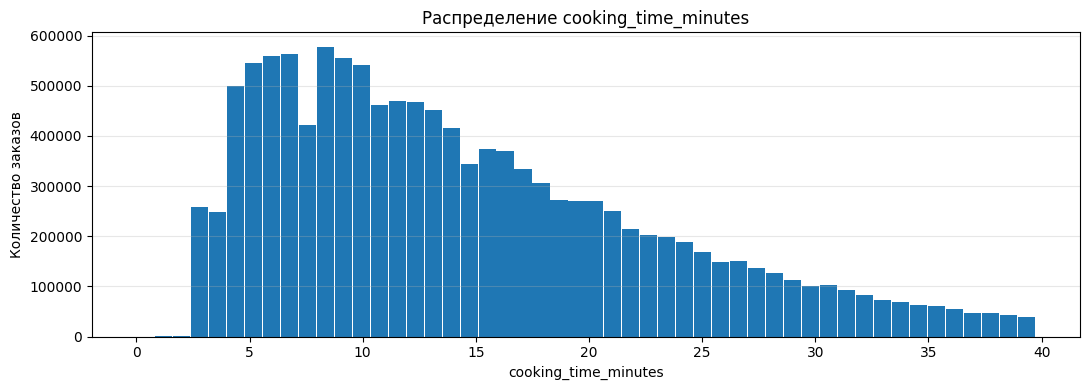

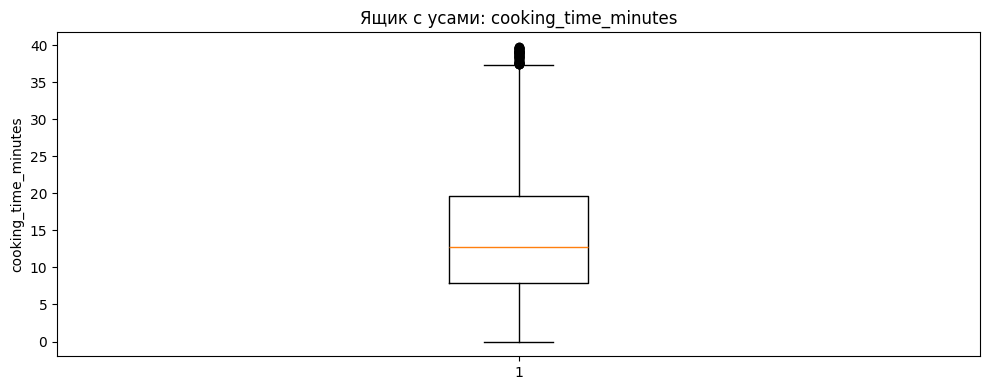

In [10]:
rows_after_outliers = valid_rows
outlier_count = 0

if len(target_statistics) > 0:
    q1 = target_statistics["q1"]
    q3 = target_statistics["q3"]
    iqr = q3 - q1

    if iqr > 0:
        lower_bound = q1 - 1.5 * iqr
        if lower_bound < 0:
            lower_bound = 0.0
        upper_bound = q3 + 1.5 * iqr
        print(f"Границы фильтрации: {lower_bound:.3f} — {upper_bound:.3f} минут")

        lower_outliers = df.filter(F.col(target_col) < lower_bound)
        upper_outliers = df.filter(F.col(target_col) > upper_bound)
        outlier_count = lower_outliers.count() + upper_outliers.count()
        print(f"Строк за границами: {outlier_count} ({outlier_count / valid_rows:.2%})")

        df = df.filter(F.col(target_col) >= lower_bound)
        df = df.filter(F.col(target_col) <= upper_bound)
        rows_after_outliers = df.count()

# Повторные расчёты показывают результат выбранной очистки.
print(f"После обработки выбросов: {rows_after_outliers} строк")
target_statistics_after = column_statistics(df, target_col)
plot_histogram(df, target_col)
plot_boxplot(df, target_col, target_statistics_after)

### 7. Пропуски в числовых признаках

После удаления строк повторно считаем доли пропусков. В рамках этой работы исключаем `num_*` с долей пропусков **более 50%**: большую часть такого столбца пришлось бы восстанавливать искусственно. Это выбранное упрощение, а не доказательство бесполезности признака.

В оставшихся числовых столбцах пропуски заполняем **медианой** наблюдаемых значений.

Цель и время заказа не заполняем. Их пропуски обработаны отдельно.

In [11]:
missing_current = missing_summary(df, rows_after_outliers)
kept_num_cols = []
dropped_num_cols = []

for column in num_cols:
    share = missing_current[column] / rows_after_outliers
    if share > missing_threshold:
        dropped_num_cols.append(column)
        df = df.drop(column)  # Удаляем один столбец
        print(f"Удалён {column}: доля пропусков {share:.2%}")
    else:
        kept_num_cols.append(column)

numeric_fill_values = {}
for column in kept_num_cols:
    if missing_current[column] > 0:
        observed_values = df.filter(F.col(column).isNotNull())
        quantiles = observed_values.approxQuantile(column, [0.5], 0.001)
        if len(quantiles) > 0:
            median_value = quantiles[0]
            numeric_fill_values[column] = median_value
            df = df.fillna({column: median_value})
            print(f"{column}: заполнено {missing_current[column]} пропусков медианой {median_value:.4f}")

num_33: 39 пропусков (0.00%)
num_40: 193 пропусков (0.00%)
num_47: 37 пропусков (0.00%)
num_54: 76 пропусков (0.00%)
num_61: 120 пропусков (0.00%)
num_68: 26 пропусков (0.00%)
num_75: 311 пропусков (0.00%)
num_131: 1055 пропусков (0.01%)
num_132: 1055 пропусков (0.01%)
num_133: 1055 пропусков (0.01%)
num_134: 1055 пропусков (0.01%)
num_135: 1055 пропусков (0.01%)
num_136: 1055 пропусков (0.01%)
num_137: 1055 пропусков (0.01%)
num_138: 1055 пропусков (0.01%)
num_139: 3410635 пропусков (27.61%)


num_140: 3410635 пропусков (27.61%)
num_141: 3410635 пропусков (27.61%)
num_142: 3410635 пропусков (27.61%)
num_143: 1055 пропусков (0.01%)
num_144: 1055 пропусков (0.01%)
num_145: 3486699 пропусков (28.22%)


num_146: 3486699 пропусков (28.22%)


num_147: 3486699 пропусков (28.22%)


num_148: 3486699 пропусков (28.22%)
num_149: 1055 пропусков (0.01%)


num_150: 3189595 пропусков (25.82%)


... (70 outputs left out)

num_181: заполнено 3189595 пропусков медианой 0.0180


num_182: заполнено 3189595 пропусков медианой 0.0159


num_183: заполнено 3189595 пропусков медианой 0.0172


num_185: заполнено 1 пропусков медианой 0.0188


### 8. Пропуски в бинарных и категориальных признаках

Проверим каждый `bin_*` и `cat_*` отдельно, включая вывод нулевых количеств

In [12]:
# Проверяем наличие пропусков в бинарных и категориальных признаках.
discrete_columns = bin_cols + cat_cols
total_discrete_missing = 0

for column in discrete_columns:
    missing_rows = df.filter(F.col(column).isNull())
    missing_count = missing_rows.count()
    total_discrete_missing = total_discrete_missing + missing_count
    print(f"{column}: пропусков — {missing_count}")

print(f"Всего пропусков в бинарных и категориальных признаках: {total_discrete_missing}")

bin_0: пропусков — 0
bin_1: пропусков — 0
bin_2: пропусков — 0
cat_0: пропусков — 0
cat_1: пропусков — 0
cat_2: пропусков — 0
cat_3: пропусков — 0
cat_4: пропусков — 0
cat_5: пропусков — 0
Всего пропусков в бинарных и категориальных признаках: 0


В выполненной проверке **во всех девяти столбцах число пропусков равно нулю**.

### 9. Корреляции числовых признаков с целью

Для каждого оставшегося `num_*` вычислим **коэффициент корреляции Пирсона** с временем приготовления. Он показывает направление и силу линейной связи двух числовых величин.

$$
r = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\,
 \sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}
$$

| Обозначение | Значение |
|---|---|
| `xᵢ` | Значение выбранного числового признака в строке i |
| `yᵢ` | Время приготовления в той же строке |
| `x̄`, `ȳ` | Средние значения признака и времени приготовления |
| `n` | Число наблюдений, участвующих в расчёте |


В числителе суммируются произведения отклонений от средних: они показывают, меняются ли величины в одном направлении. Знаменатель нормирует результат, учитывая разброс обеих величин, поэтому `r` находится в диапазоне от −1 до 1.

* `r > 0` — большему значению признака в среднем соответствует большее время.
* `r < 0` — большему значению признака в среднем соответствует меньшее время.
* Чем ближе `|r|` к 1, тем сильнее линейная связь. Значение около 0 означает слабую линейную связь, но не исключает нелинейной зависимости.

Если признак постоянный, его отклонения от среднего равны нулю, знаменатель становится нулевым и коэффициент не определён.

Так как формула Пирсона использует средние и числовые отклонения, то категориальные признаки невключены.

Выделяем до пяти числовых признаков, наиболее сильно коррелирующих со временем приготовления, и подробно показываем их распределения.

In [13]:
correlation_results = []
for column in kept_num_cols:
    # Один вызов — одна пара столбцов.
    correlation = df.stat.corr(column, target_col)

    # Числено определяем силу связи независимо от знака
    correlation_results.append((abs(correlation), column, correlation))


correlation_results.sort(reverse=True)
important_num_cols = []
for result in correlation_results[:top_features_count]:
    column = result[1]
    correlation = result[2]
    important_num_cols.append(column)
    print(f"{column}: корреляция с целью {correlation}")

num_184: корреляция с целью 0.6026364890968922
num_2: корреляция с целью 0.5504210923506477
num_59: корреляция с целью 0.5327198091211779
num_66: корреляция с целью 0.5326492269700732
num_45: корреляция с целью 0.532410616480091


### 10. Статистики и распределения выбранных числовых признаков
Для выбранных признаков показываем среднее, отклонение, минимум, максимум, квартили, гистограммы и ящики с усами. Отрицательные значения `num_*` не считаем ошибкой только из-за знака.

+-------+--------------------+
|summary|             num_184|
+-------+--------------------+
|  count|            12354984|
|   mean|-0.03888007107912998|
| stddev|  0.9671572405262513|
|    min|          -5.1993375|
|    max|           5.1993375|
+-------+--------------------+



num_184: Q1=-0.771, медиана=0.033
num_184: Q3=0.626, P95=1.546


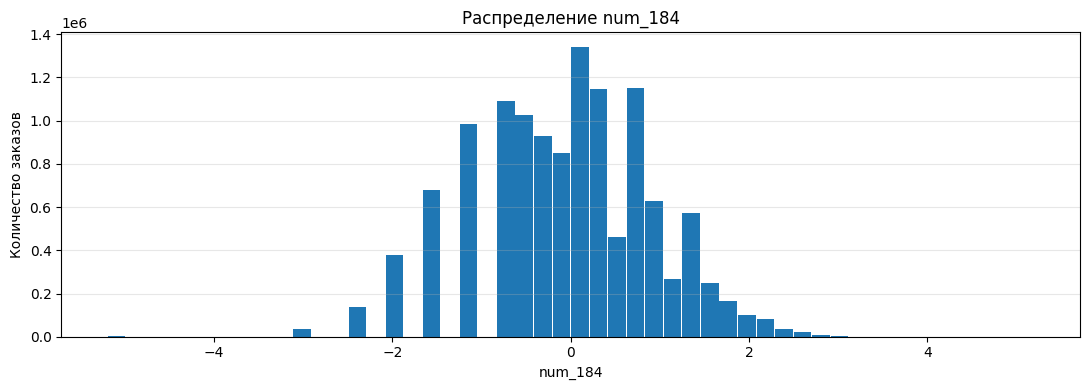

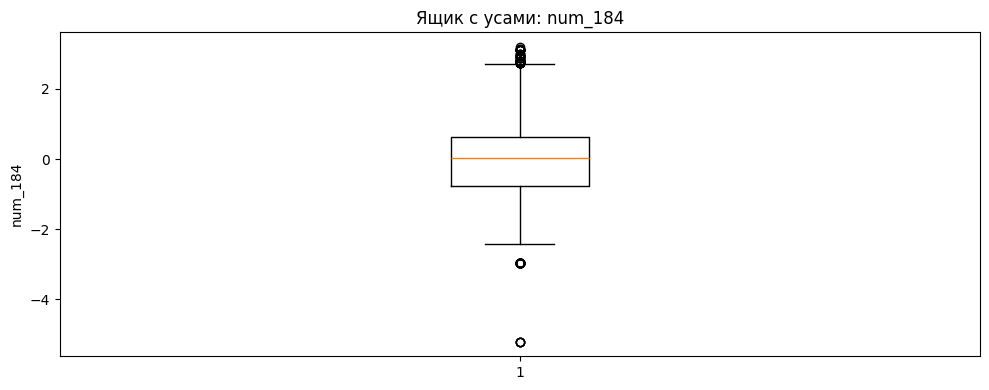

+-------+--------------------+
|summary|               num_2|
+-------+--------------------+
|  count|            12354984|
|   mean|-0.04820387399031...|
| stddev|  0.9719330964388193|
|    min|          -5.1993375|
|    max|           5.1993375|
+-------+--------------------+



num_2: Q1=-0.704, медиана=-0.038
num_2: Q3=0.617, P95=1.535


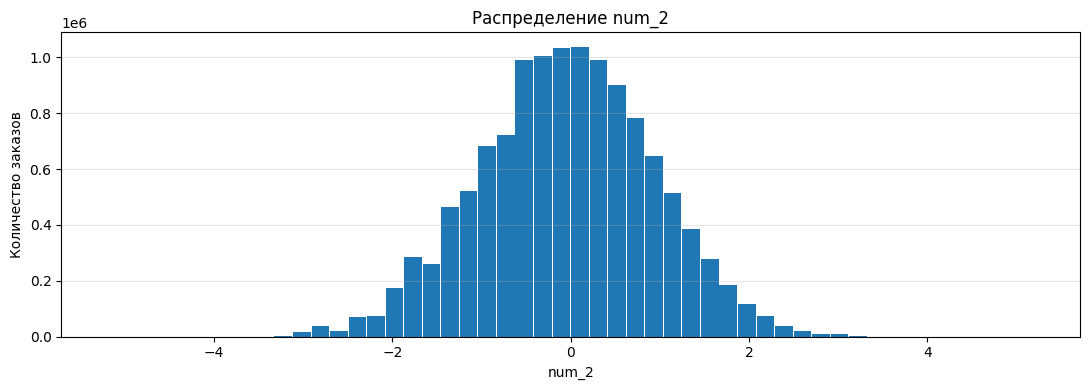

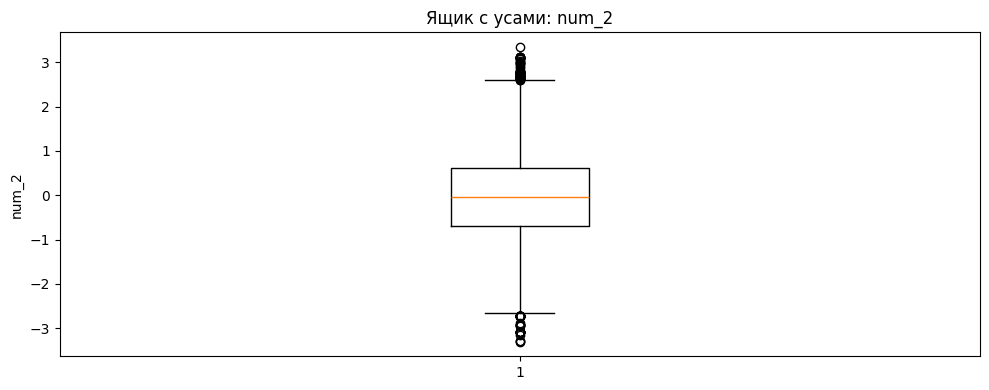

+-------+--------------------+
|summary|              num_59|
+-------+--------------------+
|  count|            12354984|
|   mean|-0.05717630995797615|
| stddev|  0.9670230928575246|
|    min|          -2.2082183|
|    max|           5.1993375|
+-------+--------------------+



num_59: Q1=-0.713, медиана=-0.045
num_59: Q3=0.609, P95=1.517


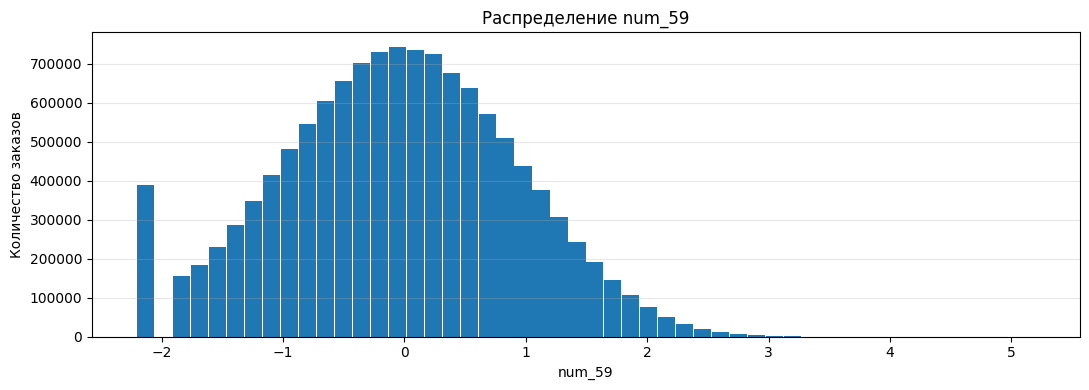

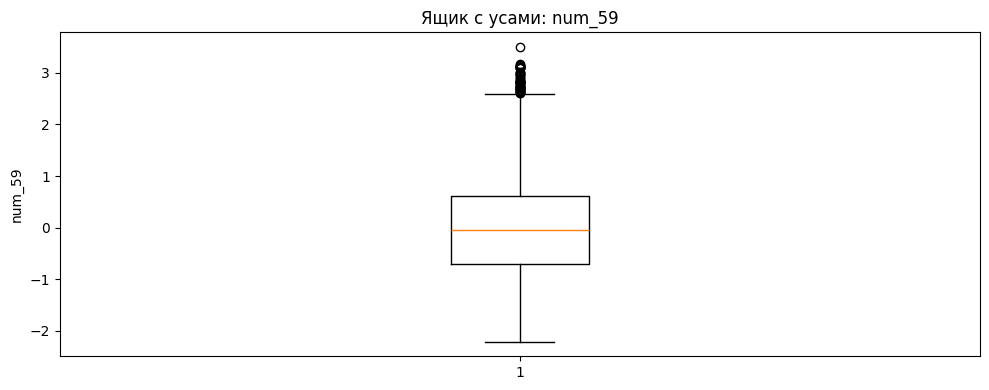

+-------+--------------------+
|summary|              num_66|
+-------+--------------------+
|  count|            12354984|
|   mean|-0.06044112057435152|
| stddev|  0.9683864571629598|
|    min|          -2.2101343|
|    max|           5.1993375|
+-------+--------------------+



num_66: Q1=-0.720, медиана=-0.049
num_66: Q3=0.607, P95=1.517


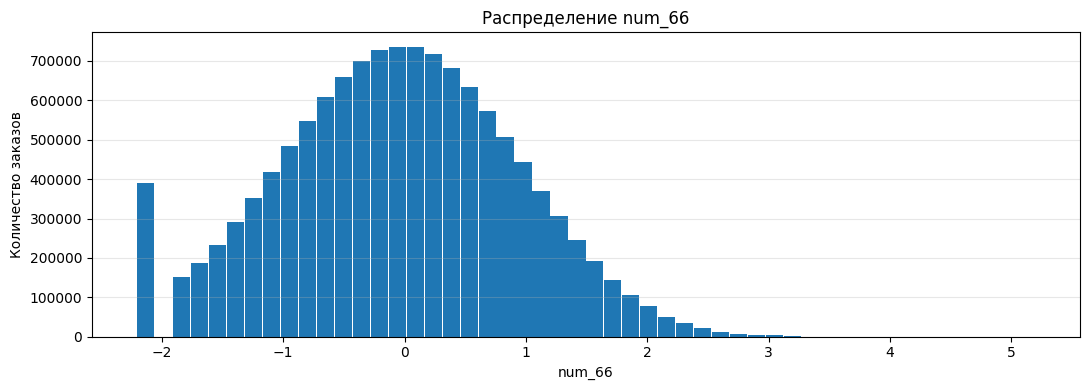

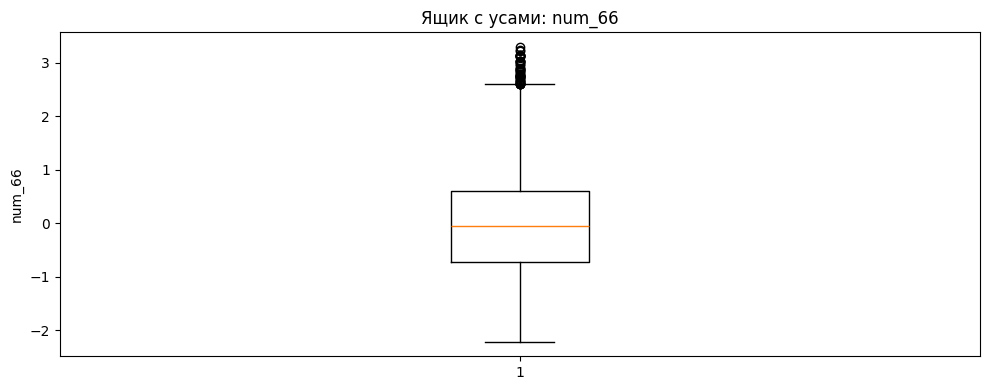

+-------+-------------------+
|summary|             num_45|
+-------+-------------------+
|  count|           12354984|
|   mean|-0.0574159689978673|
| stddev| 0.9670659113554599|
|    min|         -2.2084675|
|    max|          5.1993375|
+-------+-------------------+



num_45: Q1=-0.713, медиана=-0.047
num_45: Q3=0.609, P95=1.517


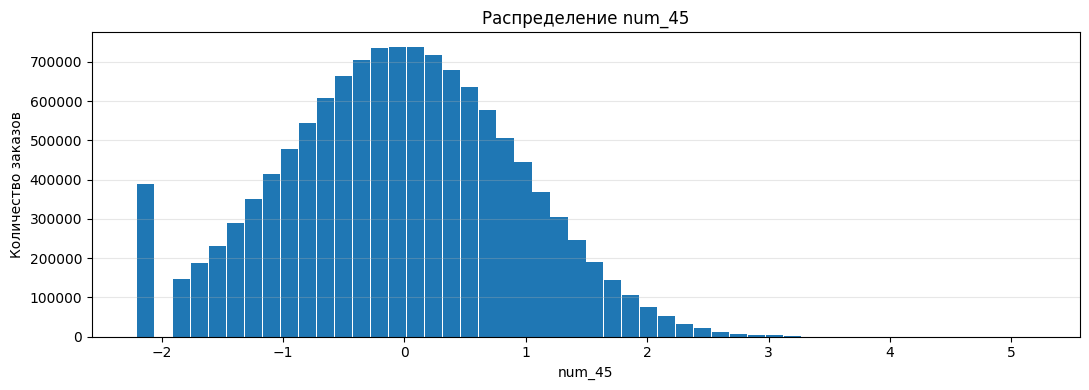

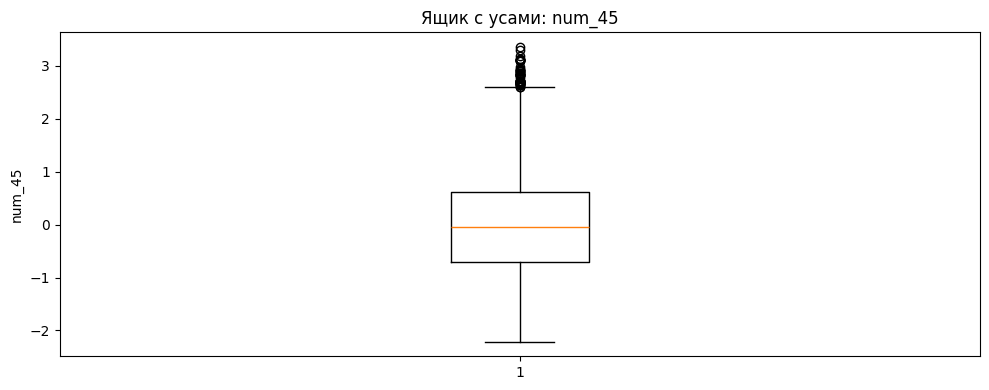

In [14]:
for column in important_num_cols:
    statistics = column_statistics(df, column)
    plot_histogram(df, column)
    plot_boxplot(df, column, statistics)

### 11. Распределения бинарных и категориальных признаков
Покажем частоты значений и среднее время приготовления в тех же группах. Для большого числа категорий рисуем только 15 наиболее частых. Размер группы важен: среднее по редкой категории менее устойчиво

+-----+-------+
|bin_0|count  |
+-----+-------+
|0.0  |6425443|
|1.0  |5929541|
+-----+-------+



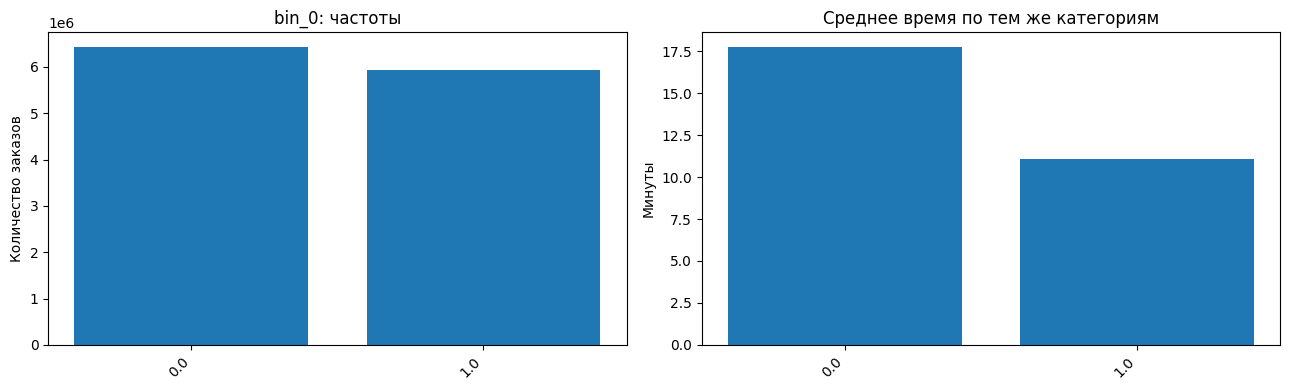

+-----+-------+
|bin_1|count  |
+-----+-------+
|1.0  |8369465|
|0.0  |3985519|
+-----+-------+



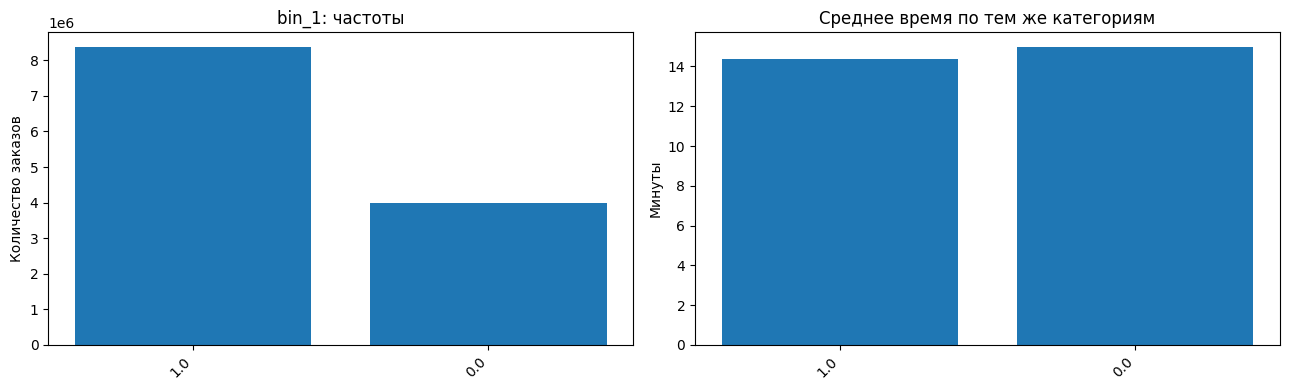

+-----+-------+
|bin_2|count  |
+-----+-------+
|1.0  |9165389|
|0.0  |3189595|
+-----+-------+



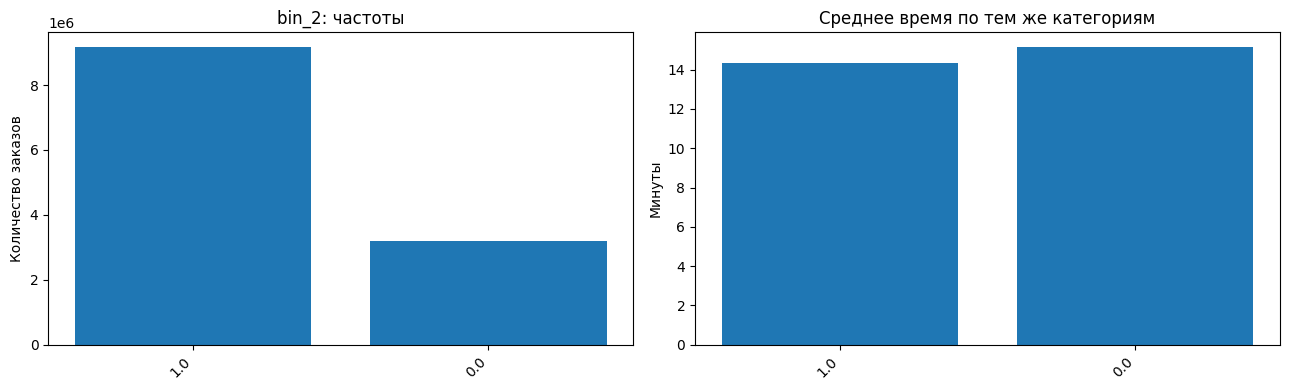

+-----+-----+
|cat_0|count|
+-----+-----+
|251  |17070|
|1327 |15762|
|889  |15536|
|94   |14551|
|985  |12440|
|1544 |12367|
|171  |11998|
|753  |11827|
|31   |11668|
|3309 |11296|
|2130 |11038|
|2360 |11021|
|708  |10604|
|1151 |10395|
|1277 |10287|
+-----+-----+
only showing top 15 rows



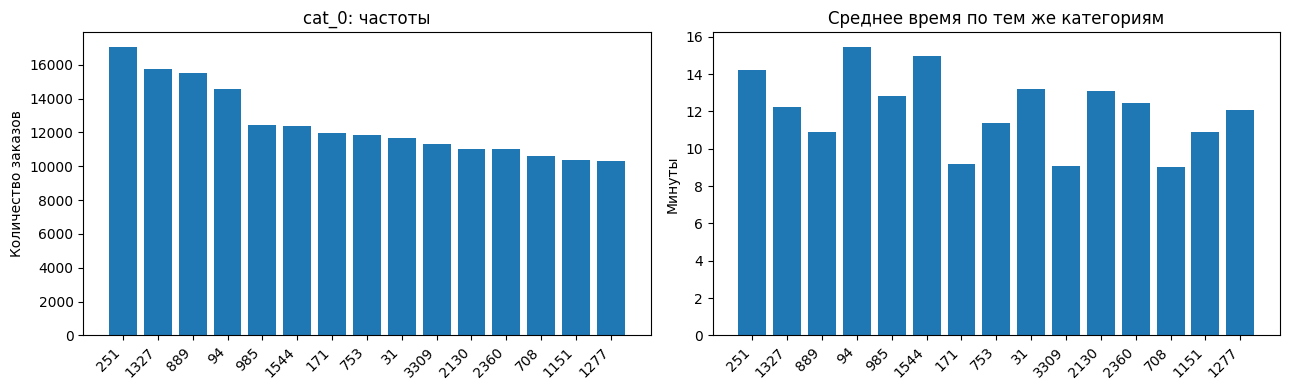

+-----+-------+
|cat_1|count  |
+-----+-------+
|1    |2751014|
|7    |905616 |
|2    |752935 |
|34   |580763 |
|6    |318858 |
|8    |288093 |
|82   |122162 |
|14   |99017  |
|50   |95457  |
|22   |86245  |
|120  |80185  |
|94   |76872  |
|147  |76843  |
|49   |66959  |
|86   |52512  |
+-----+-------+
only showing top 15 rows



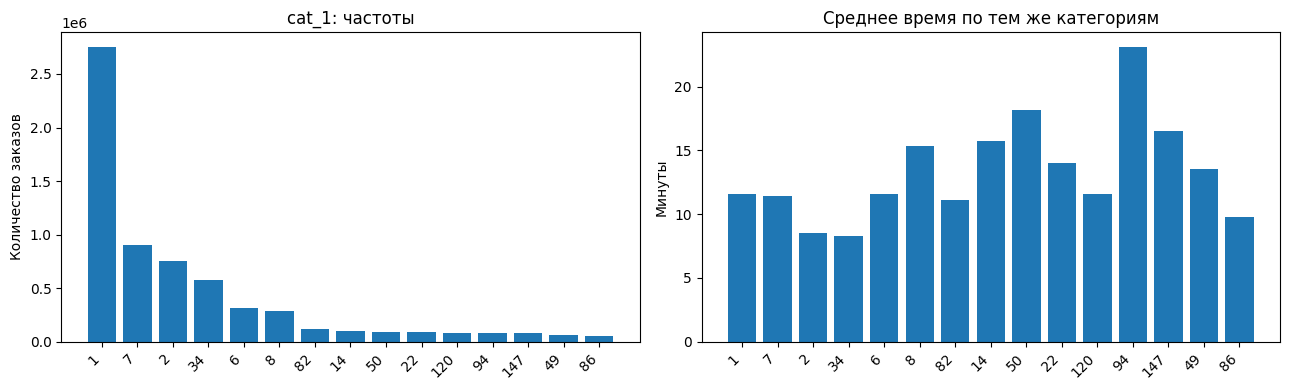

+-----+-----+
|cat_2|count|
+-----+-----+
|120  |36892|
|172  |28297|
|381  |27067|
|361  |25194|
|196  |24690|
|758  |23734|
|641  |22054|
|170  |21997|
|1091 |21357|
|555  |20674|
|148  |20569|
|634  |20311|
|513  |20159|
|111  |20102|
|478  |19647|
+-----+-----+
only showing top 15 rows



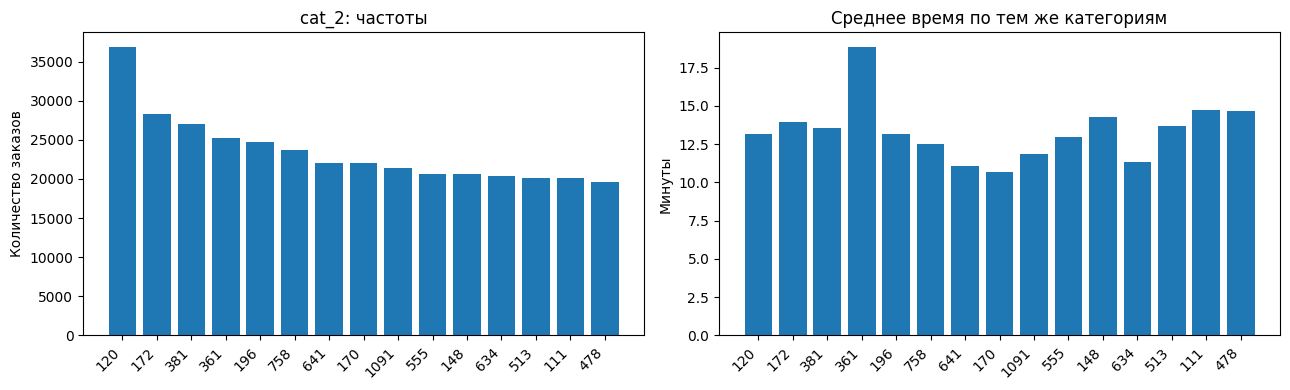

+-----+-----+
|cat_3|count|
+-----+-----+
|827  |12388|
|121  |10576|
|1085 |8874 |
|916  |8838 |
|86   |8589 |
|706  |8379 |
|288  |8280 |
|244  |8213 |
|2077 |7854 |
|1654 |7630 |
|577  |7588 |
|2351 |7503 |
|1805 |7174 |
|2554 |6856 |
|6266 |6807 |
+-----+-----+
only showing top 15 rows



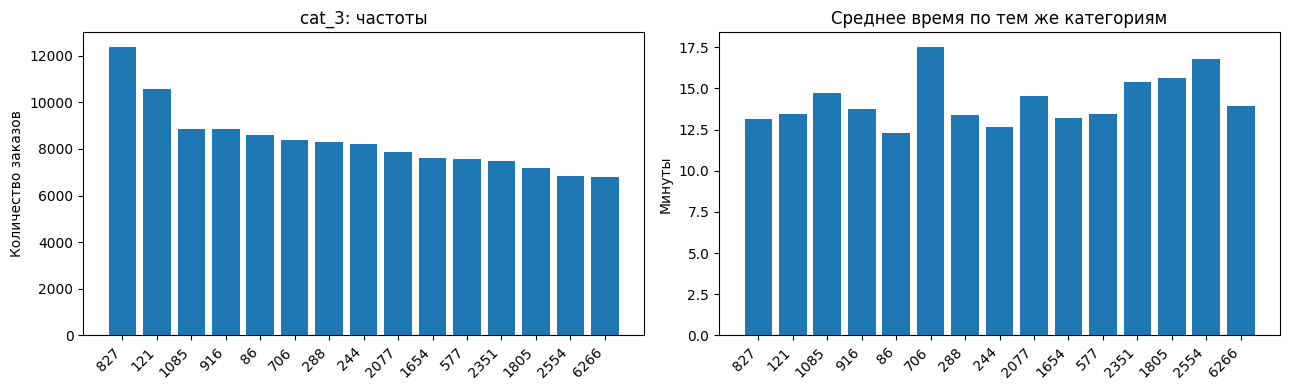

+-----+-------+
|cat_4|count  |
+-----+-------+
|1    |8143779|
|2    |4204383|
|3    |6822   |
+-----+-------+



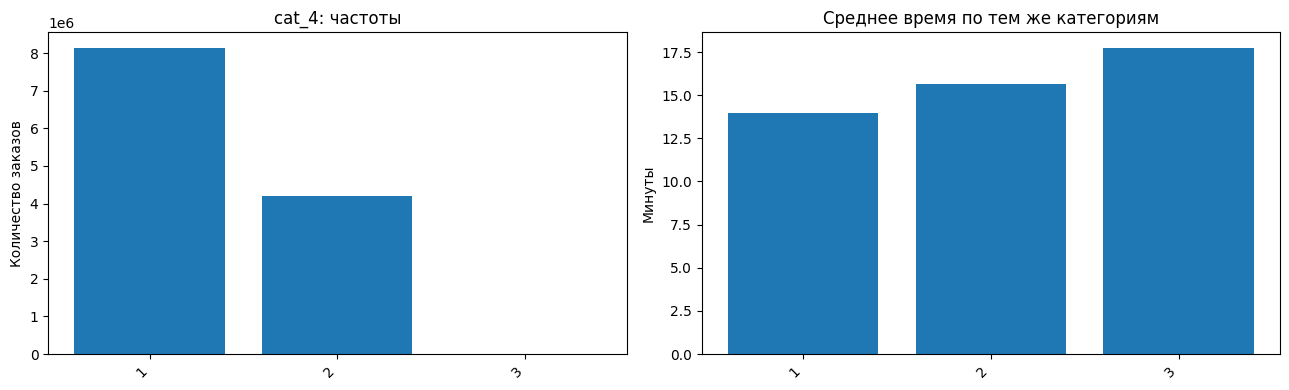

+-----+--------+
|cat_5|count   |
+-----+--------+
|2    |11455505|
|27   |88207   |
|293  |1574    |
|568  |1567    |
|218  |1376    |
|563  |1230    |
|29   |1056    |
|517  |1019    |
|4058 |999     |
|1026 |997     |
|1195 |981     |
|598  |966     |
|3064 |941     |
|1326 |871     |
|712  |868     |
+-----+--------+
only showing top 15 rows



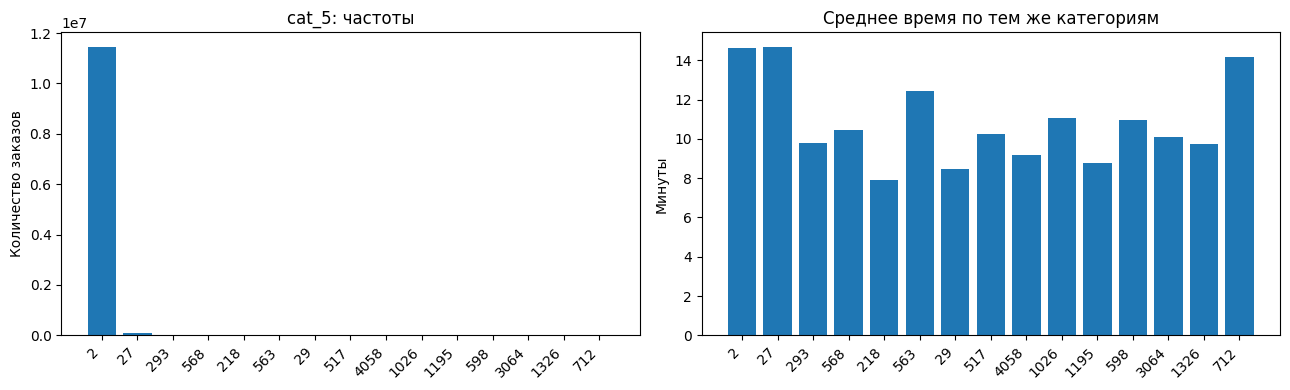

In [15]:
def plot_category(data, column, top_n=15, sort_by_value=False):
    frequencies = data.groupBy(column).count()
    # Категории обычно упорядочиваем по частоте; часы — по времени.
    if sort_by_value:
        frequencies = frequencies.orderBy(column) # Сортируем от меньшего к большему
    else:
        frequencies = frequencies.orderBy(F.desc("count"), F.asc(column)) #  От большего кол-ва заказов к меньшему, а код категории от меньшего к большему
    frequencies.show(top_n, truncate=False)
    rows = frequencies.limit(top_n).collect()

    labels = []
    counts = []
    mean_times = []
    for row in rows:
        category = row[column]
        labels.append(category)
        counts.append(row["count"])

        # Сначала отбираем категорию, затем считаем среднее по её строкам.
        category_rows = data.filter(F.col(column) == category)
        mean_time = category_rows.select(F.mean(target_col)).first()[0]
        mean_times.append(mean_time)

    if len(labels) == 0:
        return
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    positions = list(range(len(labels)))
    axes[0].bar(positions, counts)
    axes[0].set_title(f"{column}: частоты")
    axes[0].set_ylabel("Количество заказов")
    axes[1].bar(positions, mean_times)
    axes[1].set_title("Среднее время по тем же категориям") # Сколько минут в среднем готовились заказы этой категории
    axes[1].set_ylabel("Минуты")
    for ax in axes:
        ax.set_xticks(positions)
        ax.set_xticklabels(labels, rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

for column in discrete_columns:
    plot_category(df, column, top_categories_count)

### 12. Распределение наблюдений по времени
Получим суточную динамику и распределение по часам. Дополнительные столбцы создаём во временной таблице для анализа

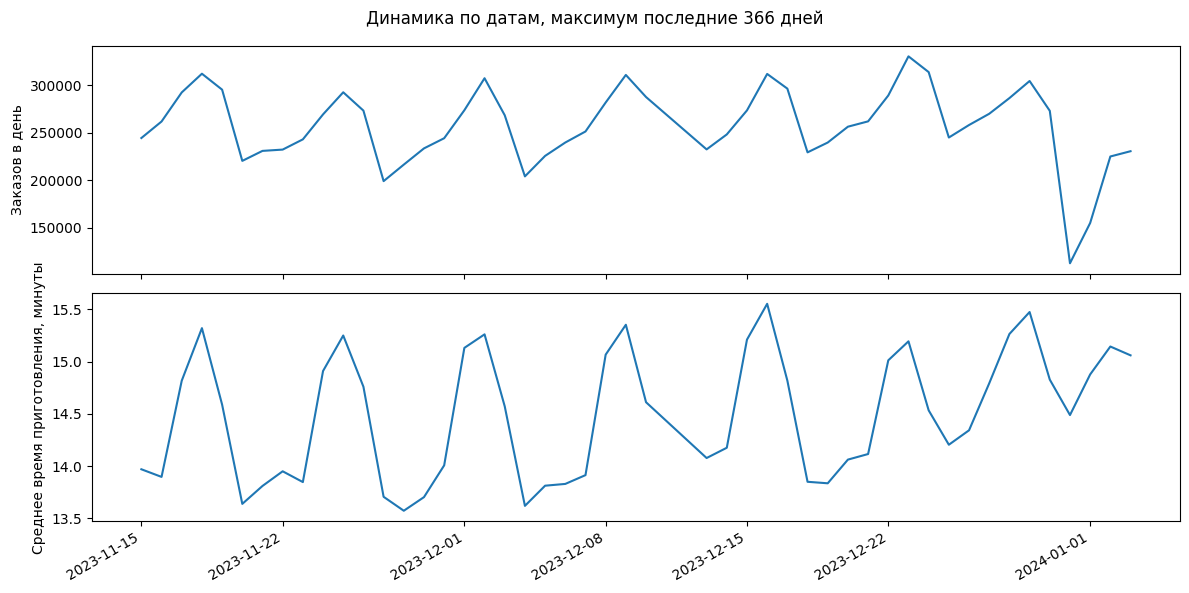

+----------------+-------+
|observation_hour|count  |
+----------------+-------+
|0               |23564  |
|1               |22952  |
|2               |31250  |
|3               |52391  |
|4               |94452  |
|5               |224308 |
|6               |397688 |
|7               |585942 |
|8               |745623 |
|9               |869767 |
|10              |904033 |
|11              |931052 |
|12              |969023 |
|13              |1012506|
|14              |1068829|
|15              |1103467|
|16              |1040965|
|17              |882946 |
|18              |644011 |
|19              |388325 |
|20              |189008 |
|21              |83195  |
|22              |56547  |
|23              |33140  |
+----------------+-------+



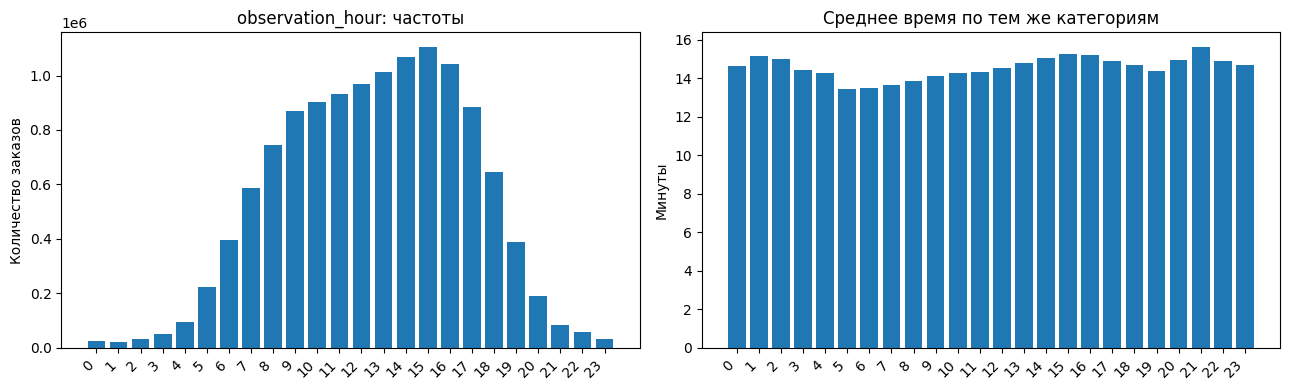

In [16]:
time_data = df.withColumn("observation_date", F.to_date(timestamp_col))
time_data = time_data.withColumn("observation_hour", F.hour(timestamp_col))

# Для рисунка берём последние 366 дат, чтобы не собирать неограниченную историю.
dates = time_data.select("observation_date").distinct()
dates = dates.orderBy(F.desc("observation_date"))
date_rows = dates.limit(366).collect()
date_rows.reverse()  # На рисунке даты идут от ранних к поздним.

date_labels = []
daily_counts = []
daily_means = []
for row in date_rows:
    date = row["observation_date"]
    day_data = time_data.filter(F.col("observation_date") == date)
    date_labels.append(date)
    daily_counts.append(day_data.count())
    daily_means.append(day_data.select(F.mean(target_col)).first()[0])

if len(date_labels) > 0:
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    axes[0].plot(date_labels, daily_counts)
    axes[0].set_ylabel("Заказов в день")
    axes[1].plot(date_labels, daily_means)
    axes[1].set_ylabel("Среднее время приготовления, минуты")
    fig.suptitle("Динамика по датам, максимум последние 366 дней")
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

plot_category(time_data, "observation_hour", 24, sort_by_value=True)

### 13. Корреляции между выбранными признаками
Построим небольшую матрицу для выбранных `num_*` и цели

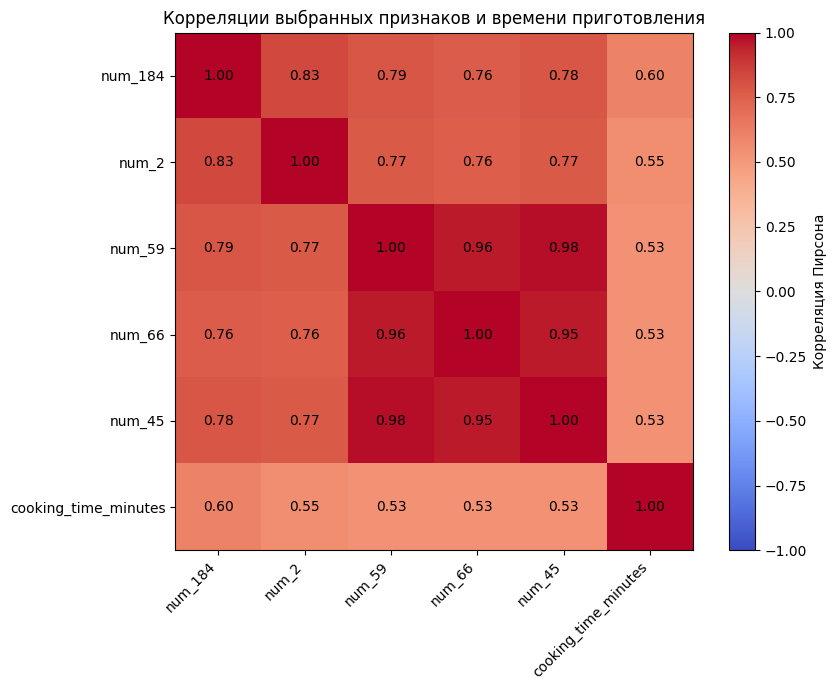

In [17]:
matrix_columns = important_num_cols + [target_col]
matrix = []
for first_column in matrix_columns:
    matrix_row = []
    for second_column in matrix_columns:
        correlation = df.stat.corr(first_column, second_column)
        matrix_row.append(correlation)
    matrix.append(matrix_row)

fig, ax = plt.subplots(figsize=(9, 7))
image_plot = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
positions = list(range(len(matrix_columns)))
ax.set_xticks(positions)
ax.set_yticks(positions)
ax.set_xticklabels(matrix_columns, rotation=45, ha="right")
ax.set_yticklabels(matrix_columns)

for i in range(len(matrix_columns)):
    for j in range(len(matrix_columns)):
        label = "—"
        if math.isfinite(matrix[i][j]):
            label = f"{matrix[i][j]:.2f}"
        ax.text(j, i, label, ha="center", va="center")
fig.colorbar(image_plot, ax=ax, label="Корреляция Пирсона")
ax.set_title("Корреляции выбранных признаков и времени приготовления")
plt.tight_layout()
plt.show()

### 14. Сохранение

In [18]:
# сохраняем только результат разведочного анализа и очистки
df.writeTo(processed_table).using("iceberg").createOrReplace()

26/10/29 03:11:53 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


### 15. Выводы по выполненному анализу

Среди исследованных числовых признаков выделены пять с наибольшей по модулю линейной связью с `cooking_time_minutes`:

| Признак | Корреляция Пирсона с временем приготовления |
|---|---:|
| `num_184` | 0,6026 |
| `num_2` | 0,5504 |
| `num_59` | 0,5327 |
| `num_66` | 0,5326 |
| `num_45` | 0,5324 |

**Наиболее выраженная связь обнаружена у `num_184`.** Все пять коэффициентов положительны: большим значениям этих признаков в среднем соответствует большее время приготовления.

**Выбранные признаки связаны и между собой.** Для `num_59`, `num_66` и `num_45` коэффициенты составляют примерно **0,95–0,98**. Эти признаки содержат близкую линейную информацию, поэтому их нельзя интерпретировать как три независимых фактора времени приготовления.

**Категориальные и бинарные признаки рассмотрены через группы заказов.** Графики показывают распространённость каждого значения и среднее время приготовления в соответствующей группе. Частая категория не обязательно характеризуется длительным приготовлением: количество заказов и их средняя длительность — разные показатели. Для этих признаков отдельные коэффициенты связи не рассчитывались, поэтому общий рейтинг всех типов признаков не установлен.

**Наблюдается временная изменчивость.** Среднее время приготовления меняется по датам; на графике видны повторяющиеся колебания. Это основание учитывать время наблюдения при дальнейшем изучении данных, но само по себе не доказывает, что увеличение числа заказов вызывает увеличение длительности.

Таким образом, анализ выделил `num_184` и `num_2` как признаки с наиболее выраженной линейной связью с целью, а также группу тесно связанных признаков `num_59`, `num_66`, `num_45`

In [19]:
spark.stop()  # Освобождаем ресурсы приложения на кластере.